In [1]:
import numpy as np
import matplotlib.pyplot as plt
import imodex_miri_postprocess_pipeline as imp #homemade pipeline
from scipy import ndimage
from scipy.optimize import curve_fit
from astropy.stats import sigma_clip
from astropy.io import fits
import glob
from scipy.optimize import minimize
#from collections import defaultdict
from scipy import ndimage
import math
import glob, os
import scipy.optimize as optimize
from matplotlib.colors import LogNorm
### 347.56 roll 1 PA V3
### 337.58 roll 2 PA V3

In [2]:
path_save = '/home/cperrot/Work/projet/JWST/Target/GTO/TWHydra/'
path_data = '/home/cperrot/Work/projet/JWST/Target/GTO/TWHydra/'

if not os.path.exists(path_save):
    os.makedirs(path_save)

pixscale = 0.110 # arcsec
filt     = 'F1550C'
V3i      = 4.83544897

if filt == 'F1550C':
    lam = 15.50e-6    # lambda en m
    x0  = 119.71
    y0  = 113.28

data     = fits.open(path_data+'image_TWHya_amoeba_F1550C_rollsum_data_Jy.fits')[0].data
model    = fits.open(path_data+'image_TWHya_amoeba_F1550C_rollsum_model_Jy.fits')[0].data
residual = fits.open(path_data+'image_TWHya_amoeba_F1550C_rollsum_model_residuals_Jy.fits')[0].data
ydim,xdim = np.shape(data)        

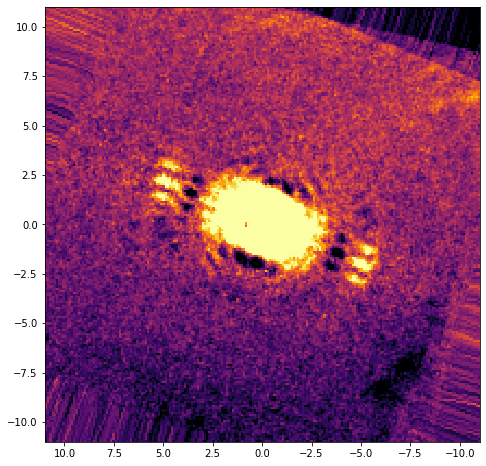

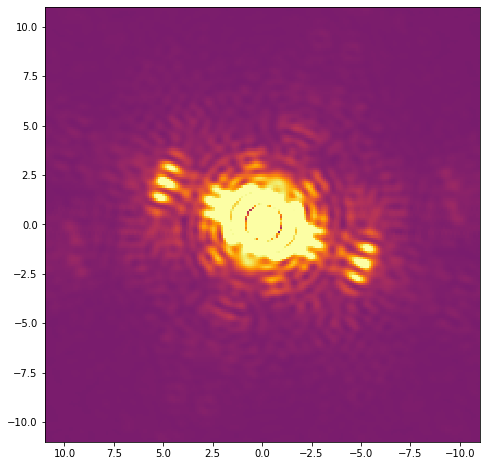

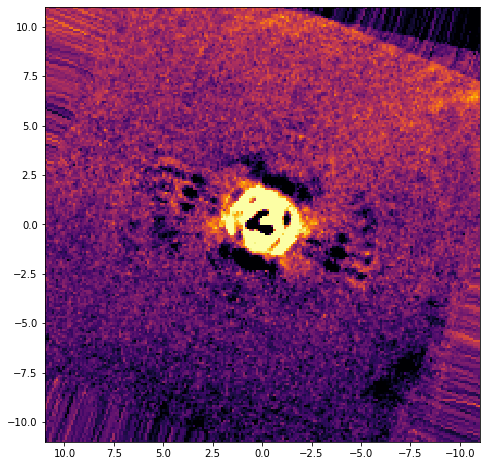

In [3]:
scale=[(xdim/2.)*pixscale,-1*(xdim/2.)*pixscale,-1*(ydim/2.)*pixscale,(ydim/2.)*pixscale]

plt.figure(figsize=(8,8))
plt.imshow(data,origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=2,extent=scale)
plt.show()
plt.figure(figsize=(8,8))
plt.imshow(model,origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=2,extent=scale)
plt.show()
plt.figure(figsize=(8,8))
plt.imshow(residual,origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=2,extent=scale)
plt.show()

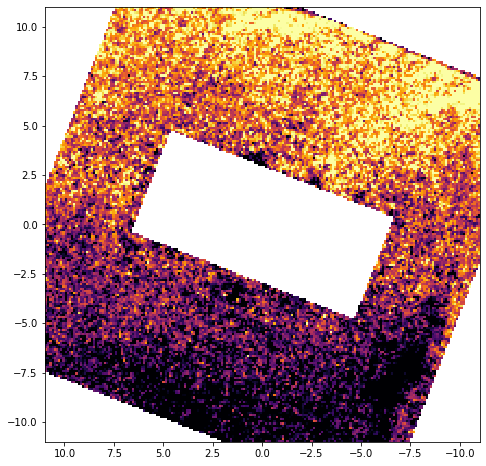

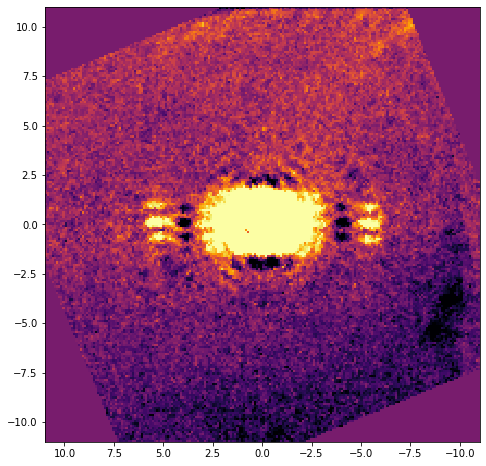

In [4]:
### 347.56 roll 1 PA V3
### 337.58 roll 2 PA V3
PAV3_1 = 347.56
PAV3_2 = 337.58
mask_edge = np.ndarray([ydim,xdim])*0+1
mask_edge = ndimage.rotate(mask_edge, V3i+16.5, reshape=False,order=0)
mask_edge[np.where(mask_edge == 0)] = math.nan

mask_cntr = np.ndarray([ydim,xdim])*0+1
mask_cntr[ydim//2-25:ydim//2+25,xdim//2-55:xdim//2+55] = 0
mask_cntr = ndimage.rotate(mask_cntr, V3i+16.5, reshape=False,order=0)
mask_cntr[np.where(mask_cntr == 0)] = math.nan


plt.figure(figsize=(8,8))
plt.imshow(mask_cntr*residual,origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=0.5,extent=scale)
plt.show()

residu_masked = residual * mask_cntr

bkg_ptrn = np.ndarray([ydim,xdim])
bkg_ptrn1 = np.ndarray([ydim,xdim])
bkg_ptrn2 = np.ndarray([ydim,xdim])
for i in range(ydim):
    for j in range(xdim):
        #bkg_ptrn[i,j] = np.nanmedian([residu_masked[i,:],residu_masked[:,j]])
        bkg_ptrn1[i,j] = np.nanmedian(residu_masked[i,:])
            
for i in range(ydim):
    for j in range(xdim):
        bkg_ptrn2[i,j] = np.nanmedian((residu_masked-bkg_ptrn1)[:,j])    

bkg_ptrn = bkg_ptrn1+bkg_ptrn2


plt.figure(figsize=(8,8))
plt.imshow(ndimage.rotate(data, PAV3_2, reshape=False,order=0),origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=2,extent=scale)
plt.show()


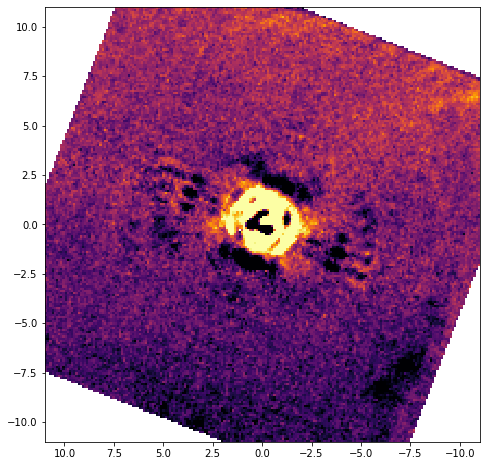

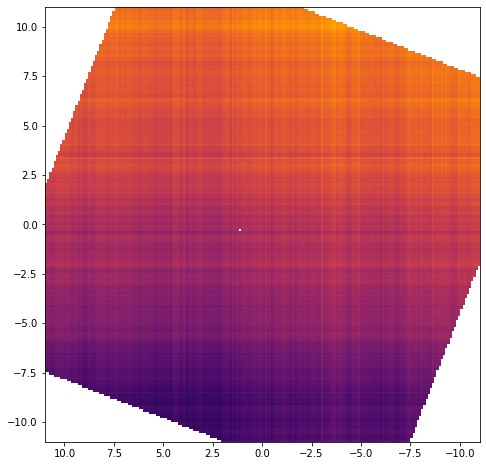

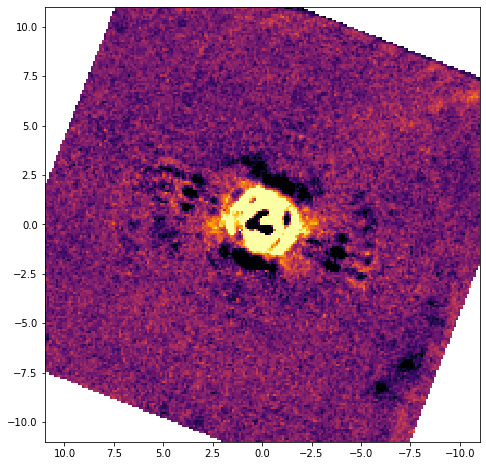

In [5]:
plt.figure(figsize=(8,8))
plt.imshow(residual*mask_edge,origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=2,extent=scale)
plt.show()

plt.figure(figsize=(8,8))
plt.imshow(bkg_ptrn*mask_edge,origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=1,extent=scale)
plt.show()


plt.figure(figsize=(8,8))
plt.imshow((residual-bkg_ptrn)*mask_edge,origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=2,extent=scale)
plt.show()


residual = residual - bkg_ptrn

In [6]:

# transmission

path_transmission = '/home/cperrot/Work/projet/JWST/Target/Calib/transmission/'
transmi_sum = fits.open(path_transmission+'F1550C_transmi_sum.fits')[0].data
transmi_max = fits.open(path_transmission+'F1550C_transmi_max.fits')[0].data


map1 = ndimage.rotate(transmi_sum, -V3i-PAV3_2, reshape=False,order=1)
map2 = ndimage.rotate(transmi_sum, -V3i-PAV3_1, reshape=False,order=1)

transmi_twh_sum = np.nanmean([map1,map2],axis=0)

map1 = ndimage.rotate(transmi_max, -V3i-PAV3_2, reshape=False,order=1)
map2 = ndimage.rotate(transmi_max, -V3i-PAV3_1, reshape=False,order=1)

transmi_twh_max = np.nanmean([map1,map2],axis=0)



### Transmission à 45° (optimale)

t_sum_45 = transmi_twh_sum.copy()
t_sum_45[np.where(np.isnan(t_sum_45))] = 0
t_sum_45 = ndimage.rotate(t_sum_45, 45.-V3i, reshape=False)
t_sum_45 = t_sum_45[xdim//2,:]
t_sum_45 = (t_sum_45[xdim//2:]+t_sum_45[0:xdim//2][::-1])/2.

t_max_45 = transmi_twh_max.copy()
t_max_45[np.where(np.isnan(t_max_45))] = 0
t_max_45 = ndimage.rotate(t_max_45, 45.-V3i, reshape=False)
t_max_45 = t_max_45[xdim//2,:]
t_max_45 = (t_max_45[xdim//2:]+t_max_45[0:xdim//2][::-1])/2.


### Transmission à 15° (pas optimale)

t_sum_15 = transmi_twh_sum.copy()
t_sum_15[np.where(np.isnan(t_sum_15))] = 0
t_sum_15 = ndimage.rotate(t_sum_15, 15.-V3i, reshape=False)
t_sum_15 = t_sum_15[xdim//2,:]
t_sum_15 = (t_sum_15[xdim//2:]+t_sum_15[0:xdim//2][::-1])/2.

t_max_15 = transmi_twh_max.copy()
t_max_15[np.where(np.isnan(t_max_15))] = 0
t_max_15 = ndimage.rotate(t_max_15, 15.-V3i, reshape=False)
t_max_15 = t_max_15[xdim//2,:]
t_max_15 = (t_max_15[xdim//2:]+t_max_15[0:xdim//2][::-1])/2.





/tmp/ipykernel_22422/2815845031.py:11: RuntimeWarning: Mean of empty slice
  transmi_twh_sum = np.nanmean([map1,map2],axis=0)
/tmp/ipykernel_22422/2815845031.py:16: RuntimeWarning: Mean of empty slice
  transmi_twh_max = np.nanmean([map1,map2],axis=0)


In [7]:
dr = 1.5*lam/6.5*180.*3600./np.pi/pixscale #pour faire une zone de 1,5*2 = 3 L/D de diametre
Y, X = np.ogrid[:ydim, :xdim]

mask = np.sqrt((X - xdim//2 +0.5)**2 + (Y- ydim//2 +0.5)**2)

### Std dev azimutale dans un anneau de 3 L/D de largeur
std      = np.ndarray(xdim//2)
std_map  = np.ndarray([xdim,xdim])*0.
mask_map = np.ndarray([xdim//2,xdim,xdim])*0.
for i in range(0,xdim//2):
    mask_sel        = (mask >= i-dr/2.) * (mask < i+dr/2.)
    mask_map[i,:,:] = mask_sel*residual
    std[i]          = np.nanstd(residual[mask_sel])  ### radial pour residual
    std_map[mask_sel]   = std[i]                         ### MAP pour residual

imp.save_fits(mask,path_save+'mask.fits')
imp.save_fits(mask_map,path_save+'mask_map.fits')


In [8]:
pixtosr = (pixscale/(3600*180/np.pi))**2 # y avait un facteur 6^2 et je sais pas pourquoi. Erreur ?
mjytojy = 1e6                          #Mjy to µjy
nbpixel = np.pi*dr**2                    #nombre de pixel dans la zone de photométrie de "dr" l/D de rayon 
coef=pixtosr*mjytojy*np.sqrt(nbpixel)*2.1000829 #np.median(out_f_co) sur le code de calcul de transmission du corono

In [9]:



### map 5 Sigma std dev en microjy par pixel avec correction de la transmission (profil radial / transmission)
imp.save_fits(5*coef*std_map/transmi_twh_max,path_save+'TWHydra_std_jy_transmi_max.fits')
imp.save_fits(5*coef*std_map/transmi_twh_sum,path_save+'TWHydra_std_jy_transmi_sum.fits')

### pareil mais en W.m-2 par pixel
imp.save_fits(5*coef*imp.flux_Jy_to_Wm(15.5,std_map)/transmi_twh_max,path_save+'TWHydra_map_std_wm2_transmi_max.fits')
imp.save_fits(5*coef*imp.flux_Jy_to_Wm(15.5,std_map)/transmi_twh_sum,path_save+'TWHydra_map_std_wm2_transmi_sum.fits')

lim_det_5sig_t15_wm = np.ndarray(xdim//2)
lim_det_5sig_t45_wm = np.ndarray(xdim//2)
### passage de Jy a W/m2/µm (les flux sont en MJy/sr mais le facteur de conversion est linéaire et donc peut être fait plus tard)
std_wm   = imp.flux_Jy_to_Wm(15.5,std)
for i in range(0,xdim//2):
    #print("{:4.3f}".format((i+0.5)*0.11),"{:4.3f}".format(coef*std_m2[i]),"{:.3e}".format(coef*std_m2_wm[i]))
    lim_det_5sig_t15_wm[i] = 5*coef*std_wm[i]/t_sum_15[i]
    lim_det_5sig_t45_wm[i] = 5*coef*std_wm[i]/t_sum_45[i]
    #print("{:4.3f}".format(i*0.11),"{:.3e}".format(lim_det_5sig_t15_wm[i]),"{:.3e}".format(lim_det_5sig_t45_wm[i]))
    print("{:4.3f}".format(i*0.11),"{:.3e}".format(lim_det_5sig_t15_wm[i]))

0.000 1.558e-16
0.110 4.788e-17
0.220 2.200e-17
0.330 1.397e-17
0.440 1.043e-17
0.550 8.459e-18
0.660 6.615e-18
0.770 4.777e-18
0.880 3.304e-18
0.990 2.355e-18
1.100 1.856e-18
1.210 1.503e-18
1.320 1.190e-18
1.430 9.877e-19
1.540 9.321e-19
1.650 9.330e-19
1.760 9.464e-19
1.870 9.006e-19
1.980 8.003e-19
2.090 6.934e-19
2.200 6.127e-19
2.310 5.502e-19
2.420 4.898e-19
2.530 4.249e-19
2.640 3.602e-19
2.750 2.998e-19
2.860 2.581e-19
2.970 2.338e-19
3.080 2.147e-19
3.190 1.983e-19
3.300 1.906e-19
3.410 1.868e-19
3.520 1.909e-19
3.630 2.036e-19
3.740 2.296e-19
3.850 2.446e-19
3.960 2.489e-19
4.070 2.500e-19
4.180 2.472e-19
4.290 2.349e-19
4.400 2.165e-19
4.510 1.849e-19
4.620 1.655e-19
4.730 1.536e-19
4.840 1.491e-19
4.950 1.480e-19
5.060 1.485e-19
5.170 1.496e-19
5.280 1.512e-19
5.390 1.519e-19
5.500 1.516e-19
5.610 1.460e-19
5.720 1.431e-19
5.830 1.400e-19
5.940 1.293e-19
6.050 1.251e-19
6.160 1.252e-19
6.270 1.202e-19
6.380 1.365e-19
6.490 1.101e-18
6.600 9.207e-18
6.710 -2.327e-17
6.820 7

/tmp/ipykernel_22422/3893052843.py:2: RuntimeWarning: divide by zero encountered in true_divide
  imp.save_fits(5*coef*std_map/transmi_twh_max,path_save+'TWHydra_std_jy_transmi_max.fits')
/tmp/ipykernel_22422/3893052843.py:2: RuntimeWarning: invalid value encountered in true_divide
  imp.save_fits(5*coef*std_map/transmi_twh_max,path_save+'TWHydra_std_jy_transmi_max.fits')
/tmp/ipykernel_22422/3893052843.py:3: RuntimeWarning: divide by zero encountered in true_divide
  imp.save_fits(5*coef*std_map/transmi_twh_sum,path_save+'TWHydra_std_jy_transmi_sum.fits')
/tmp/ipykernel_22422/3893052843.py:3: RuntimeWarning: invalid value encountered in true_divide
  imp.save_fits(5*coef*std_map/transmi_twh_sum,path_save+'TWHydra_std_jy_transmi_sum.fits')
/tmp/ipykernel_22422/3893052843.py:6: RuntimeWarning: divide by zero encountered in true_divide
  imp.save_fits(5*coef*imp.flux_Jy_to_Wm(15.5,std_map)/transmi_twh_max,path_save+'TWHydra_map_std_wm2_transmi_max.fits')
/tmp/ipykernel_22422/3893052843.p

In [10]:
# plot de la limite de détection


saveformat = "pdf"

fig1 = plt.figure(figsize=(10,10))
tmp = plt.imshow(5*coef*std_map/transmi_twh_max,origin='lower',cmap='inferno',interpolation='none',norm=LogNorm(),extent=scale)
cbar = fig1.colorbar(tmp)
cbar.set_label(r'5$\sigma$ Detection limit map [Jy]')
fig1.savefig(path_save+'TWHydra_std_jy_transmi_max.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig1)

fig1 = plt.figure(figsize=(10,10))
tmp = plt.imshow(5*coef*std_map/transmi_twh_sum,origin='lower',cmap='inferno',interpolation='none',norm=LogNorm(),extent=scale)
cbar = fig1.colorbar(tmp)
cbar.set_label(r'5$\sigma$ Detection limit map [Jy]')
fig1.savefig(path_save+'TWHydra_std_jy_transmi_sum.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig1)


fig1 = plt.figure(figsize=(10,10))
tmp = plt.imshow(5*coef*imp.flux_Jy_to_Wm(15.5,std_map)/transmi_twh_max,origin='lower',cmap='inferno',interpolation='none',norm=LogNorm(),extent=scale)
cbar = fig1.colorbar(tmp)
cbar.set_label(r'5$\sigma$ Detection limit map [Jy]')
fig1.savefig(path_save+'TWHydra_std_wm2_transmi_max.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig1)

fig1 = plt.figure(figsize=(10,10))
tmp = plt.imshow(5*coef*imp.flux_Jy_to_Wm(15.5,std_map)/transmi_twh_sum,origin='lower',cmap='inferno',interpolation='none',norm=LogNorm(),extent=scale)
cbar = fig1.colorbar(tmp)
cbar.set_label(r'5$\sigma$ Detection limit map [Jy]')
fig1.savefig(path_save+'TWHydra_std_wm2_transmi_sum.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig1)




fig1 = plt.figure(figsize=(10,10))
plt.plot(np.arange(0,xdim//2,1)*0.11,5*coef*std/t_sum_45,'Green',label='at 45°')
plt.plot(np.arange(0,xdim//2,1)*0.11,5*coef*std/t_sum_15,'Blue',label='at 15°')
plt.title(r'Std Dev - 5$\sigma$')
plt.xlabel('Separation [arcsec]')
plt.ylabel(r'5$\sigma$ Detection limit [Jy]')
#plt.ylabel(r'Flux [MJy.sr$^{-1}$]')
plt.yscale('log')
plt.grid(True, which="major", ls="-")
plt.grid(True, which="minor", ls="--")
plt.ylim([1e-5,1e-1])
plt.xlim([0,5.5])
plt.legend()
fig1.savefig(path_save+'TWHydra_stddev_jy.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig1)




fig1 = plt.figure(figsize=(10,7))
plt.plot(np.arange(0,xdim//2,1)*0.11,5*coef*std_wm/t_sum_45,'Green',label='at 45°')
plt.plot(np.arange(0,xdim//2,1)*0.11,5*coef*std_wm/t_sum_15,'Blue',label='at 15°')
plt.title(r'Std Dev - 5$\sigma$')
plt.xlabel('Separation [arcsec]')
plt.ylabel(r'5$\sigma$ Detection limit [W.m$^{-2}.µm^{-1}$]')
#plt.ylabel(r'Flux [MJy.sr$^{-1}$]')
plt.yscale('log')
plt.grid(True, which="major", ls="-")
plt.grid(True, which="minor", ls="--")
plt.ylim([1e-19,1e-15])
plt.xlim([0,5.5])
plt.legend()
fig1.savefig(path_save+'TWHydra_stddev_wm2.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig1)




/tmp/ipykernel_22422/3831791005.py:7: RuntimeWarning: divide by zero encountered in true_divide
  tmp = plt.imshow(5*coef*std_map/transmi_twh_max,origin='lower',cmap='inferno',interpolation='none',norm=LogNorm(),extent=scale)
/tmp/ipykernel_22422/3831791005.py:7: RuntimeWarning: invalid value encountered in true_divide
  tmp = plt.imshow(5*coef*std_map/transmi_twh_max,origin='lower',cmap='inferno',interpolation='none',norm=LogNorm(),extent=scale)
/tmp/ipykernel_22422/3831791005.py:14: RuntimeWarning: divide by zero encountered in true_divide
  tmp = plt.imshow(5*coef*std_map/transmi_twh_sum,origin='lower',cmap='inferno',interpolation='none',norm=LogNorm(),extent=scale)
/tmp/ipykernel_22422/3831791005.py:14: RuntimeWarning: invalid value encountered in true_divide
  tmp = plt.imshow(5*coef*std_map/transmi_twh_sum,origin='lower',cmap='inferno',interpolation='none',norm=LogNorm(),extent=scale)
/tmp/ipykernel_22422/3831791005.py:22: RuntimeWarning: divide by zero encountered in true_divide